# CRISP-DM Stage 3: Data Preparation
## ECG Heartbeat Classification on Edge-AI (Analog Devices MAX78002)

---

### Purpose of this Notebook
This notebook documents and executes **CRISP-DM Stage 3: Data Preparation**, directly synchronizing with the production codebase:
- [`src/data_understanding.py`](../src/data_understanding.py)
- [`src/prepare_data.py`](../src/prepare_data.py)
- [`src/dataset.py`](../src/dataset.py)

We systematically cover every requirement of the project rubric:
1. **Record Selection (Section 3.1)**: Patient-independent partitioning into Train, Validation, and Test sets.
2. **ECG Channel Selection (Section 3.2)**: Modified Lead II (MLII) selection, channel-swap handling (Record 114), and fallbacks.
3. **Beat Extraction & Segmentation (Section 3.3)**: 256-sample fixed-size windowing ($90$ pre-R, $166$ post-R) for MAX78002.
4. **Signal Preprocessing Pipeline (Section 3.4)**: Zero-phase Butterworth filtering, normalization, and outlier clamping.
5. **Label Preparation (Section 3.5)**: AAMI EC57 4-class mapping and exclusion auditing.
6. **Class Imbalance Strategy (Section 3.6)**: Class weighting, balanced sampling, and focal loss formulation.
7. **Training Data Augmentation (Section 3.7)**: Temporal jitter, amplitude scaling, noise, and baseline wander simulation.
8. **Final Dataset Generation (Section 3.8)**: Final beat count verification across Train, Validation, and Test sets.
9. **Reproducibility Audit (Section 3.9)**: Software environment, random seeds, and pipeline parameters.

In [1]:
# Imports & Setup
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add src to path
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import data_understanding as du
from dataset import ECGDataset

# Visual styling
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["figure.titlesize"] = 14
plt.style.use("seaborn-v0_8-whitegrid")

print("Loaded Data Preparation Modules Successfully.")

Loaded Data Preparation Modules Successfully.


## 3.1 Record Selection

### Patient-Independent MIT-BIH Partition (Zero Leakage)
In accordance with the standard **de Chazal et al. (2004)** protocol:
- **DS1 (Development Set, 22 records)**: Used for training, validation, and hyperparameter tuning.
  - **Train Split (17 records)**: `109, 112, 114, 115, 116, 119, 122, 124, 201, 203, 207, 208, 209, 215, 220, 223, 230`
  - **Validation Split (5 records)**: `101, 106, 108, 118, 205`
    - *Rationale*: Chosen specifically so that **all four classes (N, S, V, F)** are present in both Train and Validation sets.
- **DS2 (Final Test Set, 22 records)**: `100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234`. Kept completely untouched until final evaluation.
- **Paced Records (4 records)**: `102, 104, 107, 217` are excluded due to artificial pacemaker artifacts (`/` and `f`).

In [2]:
# Display Record Partition Summary Table
split_info = [
  {
    "Split": "DS1 — Train",
    "Record Count": len(du.DS1_TRAIN_RECORDS),
    "Records": ", ".join(du.DS1_TRAIN_RECORDS),
    "Purpose": "Model parameter training and weight updates",
  },
  {
    "Split": "DS1 — Validation",
    "Record Count": len(du.DS1_VAL_RECORDS),
    "Records": ", ".join(du.DS1_VAL_RECORDS),
    "Purpose": "Model selection, checkpointing, and hyperparameter tuning",
  },
  {
    "Split": "DS2 — Final Test",
    "Record Count": len(du.DS2_TEST_RECORDS),
    "Records": ", ".join(du.DS2_TEST_RECORDS),
    "Purpose": "Unbiased held-out generalization testing (UNTOUCHED)",
  },
  {
    "Split": "Paced (Excluded)",
    "Record Count": len(du.PACED_RECORDS),
    "Records": ", ".join(du.PACED_RECORDS),
    "Purpose": "Excluded per AAMI guidelines (artificial pacemaker pulses)",
  },
]
display(pd.DataFrame(split_info))

,Split,Record Count,Records,Purpose
0,DS1 — Train,17,"109, 112, 114, 115, 116, 119, 122, 124, 201, 2...",Model parameter training and weight updates
1,DS1 — Validation,5,"101, 106, 108, 118, 205","Model selection, checkpointing, and hyperparam..."
2,DS2 — Final Test,22,"100, 103, 105, 111, 113, 117, 121, 123, 200, 2...",Unbiased held-out generalization testing (UNTO...
3,Paced (Excluded),4,"102, 104, 107, 217",Excluded per AAMI guidelines (artificial pacem...


## 3.2 ECG Channel Selection

### Which lead is used and why?
We select **Modified Lead II (MLII)** as our primary lead across all recordings:
1. **Anatomical Alignment**: MLII closely aligns with the primary electrical depolarization vector of the human heart, producing prominent, easily detectable QRS complexes and well-defined P and T waves.
2. **Clinical Consistency**: MLII is present in **all 44 non-paced benchmark recordings** in DS1 and DS2.

### What do we do if channel orders vary?
- In 43 of the 44 records, MLII is located at **Channel Index 0**.
- In **Record 114**, the channels are reversed: Channel 0 is `V5`, and Channel 1 is `MLII`.
- Our utility `extract_lead_signal` dynamically inspects `record.sig_name` and locates the exact index of `MLII`. If an external record lacks MLII, it falls back to Channel 0.

In [3]:
# Verify lead extraction and Record 114 channel swap handling
rec100 = du.load_record("100")
_, lead100, idx100 = du.extract_lead_signal(rec100, "MLII")

rec114 = du.load_record("114")
_, lead114, idx114 = du.extract_lead_signal(rec114, "MLII")

print(
  f"Record 100: Leads={rec100.sig_names} -> Extracted {lead100} at Channel Index {idx100}"
)
print(
  f"Record 114: Leads={rec114.sig_names} -> Extracted {lead114} at Channel Index {idx114} (Channel swap resolved!)"
)

Record 100: Leads=['MLII', 'V5'] -> Extracted MLII at Channel Index 0
Record 114: Leads=['V5', 'MLII'] -> Extracted MLII at Channel Index 1 (Channel swap resolved!)


## 3.3 Beat Extraction & Segmentation

### R-Peak Fiducial Point & Fixed Input Length
- **Annotation Source**: Official expert annotations (`.atr`) providing the sample index of the local R-peak extremum.
- **Pre-R Window**: **$90$ samples** ($250.0\text{ ms}$ @ $360\text{ Hz}$). Captures atrial depolarization (P-wave) and AV nodal delay (PR interval).
- **Post-R Window**: **$166$ samples** ($461.1\text{ ms}$ @ $360\text{ Hz}$). Captures ventricular depolarization (QRS) and complete repolarization (ST segment and T-wave).
- **Final Input Length**: **$256$ samples** ($711.1\text{ ms}$).
  - Crucial Edge-AI constraint: $256 = 2^8$ samples enables clean power-of-two dyadic pooling without fractional striding on the **Analog Devices MAX78002**.
- **Boundary Handling**: Any beat occurring within the first 90 samples or last 166 samples of a recording is safely skipped and logged.

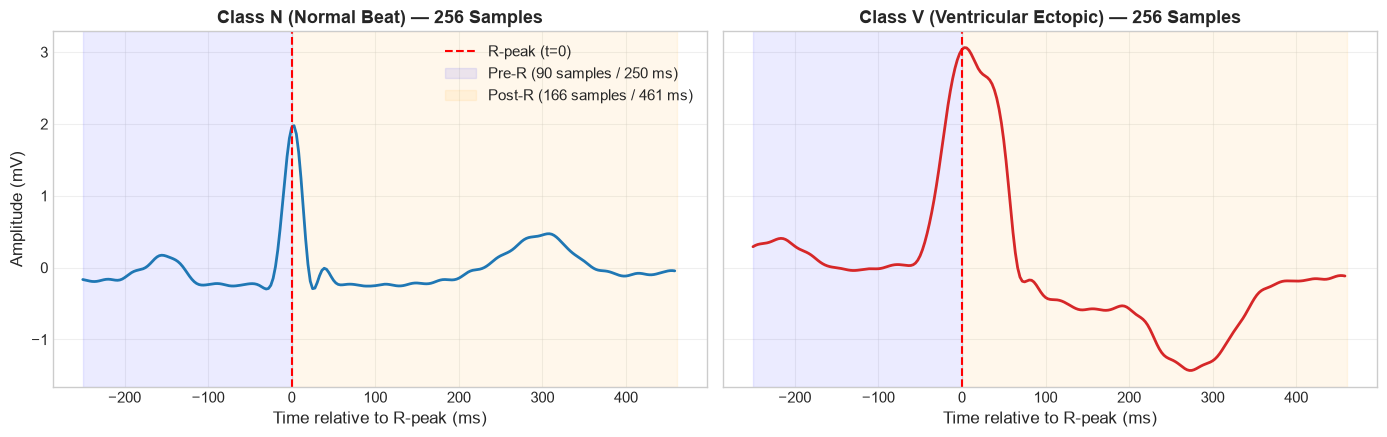

In [4]:
# Visualize segmentation on a normal beat and ventricular ectopic beat
rec119 = du.load_record("119")
sig119, _, _ = du.extract_lead_signal(rec119, "MLII")
filtered119 = du.butter_bandpass_filter(sig119)

# Find one N beat and one V beat
n_idx = [i for i, s in zip(rec119.ann_indices, rec119.ann_symbols) if s == "N"][10]
v_idx = [i for i, s in zip(rec119.ann_indices, rec119.ann_symbols) if s == "V"][10]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
time_ms = (np.arange(256) - 90) / 360.0 * 1000.0

# Plot Normal beat
beat_n = filtered119[n_idx - 90 : n_idx + 166]
ax1.plot(time_ms, beat_n, color="#1f77b4", lw=2)
ax1.axvline(0, color="red", linestyle="--", label="R-peak (t=0)")
ax1.axvspan(-250, 0, color="blue", alpha=0.08, label="Pre-R (90 samples / 250 ms)")
ax1.axvspan(0, 461.1, color="orange", alpha=0.08, label="Post-R (166 samples / 461 ms)")
ax1.set_title("Class N (Normal Beat) — 256 Samples", fontweight="bold")
ax1.set_xlabel("Time relative to R-peak (ms)")
ax1.set_ylabel("Amplitude (mV)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right")

# Plot Ventricular Ectopic beat
beat_v = filtered119[v_idx - 90 : v_idx + 166]
ax2.plot(time_ms, beat_v, color="#d62728", lw=2)
ax2.axvline(0, color="red", linestyle="--", label="R-peak (t=0)")
ax2.axvspan(-250, 0, color="blue", alpha=0.08)
ax2.axvspan(0, 461.1, color="orange", alpha=0.08)
ax2.set_title("Class V (Ventricular Ectopic) — 256 Samples", fontweight="bold")
ax2.set_xlabel("Time relative to R-peak (ms)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3.4 Signal Preprocessing Pipeline

The preprocessing pipeline executes in six strictly ordered stages:

$$\text{Raw ECG} \longrightarrow \text{Filtering} \longrightarrow \text{Segmentation} \longrightarrow \text{Normalization} \longrightarrow \text{Clipping} \longrightarrow \text{Edge Model Input}$$

### Rationale for Each Stage:
1. **Raw ECG**: 11-bit digitized analog signal in millivolts (mV). Contains respiration drift and noise.
2. **Zero-Phase Bandpass Filtering ($0.5 - 40.0\text{ Hz}$)**: Removes baseline wander ($< 0.5\text{ Hz}$) and suppresses high-frequency EMG muscle noise and 50/60 Hz powerline hum. Using `filtfilt` prevents phase distortion.
3. **Segmentation (256 samples)**: Extracts fixed-size window ($90$ pre-R, $166$ post-R) capturing full P-QRS-T complex.
4. **Per-Beat Z-Score Normalization**: $x_{\text{norm}} = \frac{x - \mu}{\sigma}$. Eliminates inter-patient amplitude disparities caused by electrode contact resistance, skin impedance, and heart orientation.
5. **Outlier Clipping ($[-3.0, 3.0]$)**: Clamps normalized values to $\pm 3$ standard deviations ($99.7\%$ of normal distribution). Eliminates motion spikes and prevents saturation in INT8 fixed-point quantization on the MAX78002.
6. **Edge Model Input**: Shaped as $(1, 256)$, compatible with 1D convolution hardware accelerators.

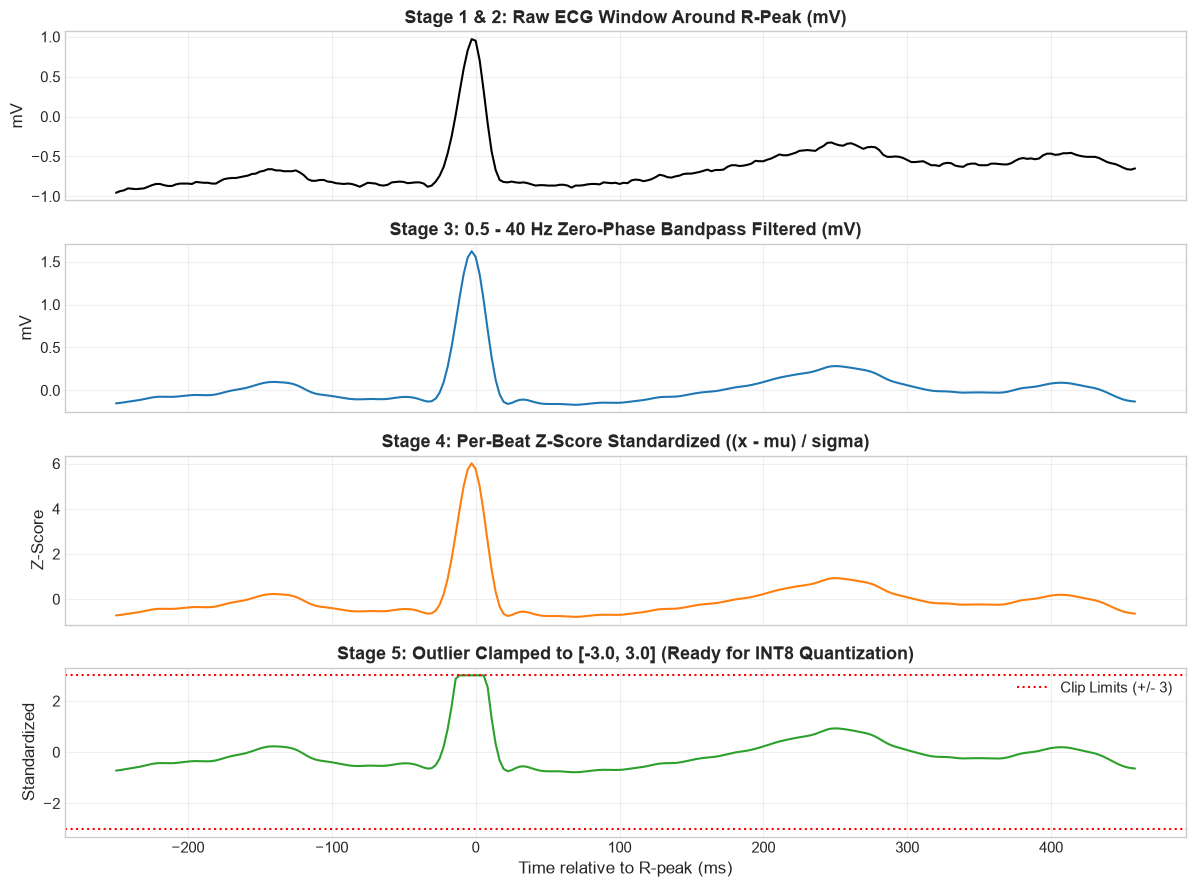

In [5]:
# Step-by-Step Visualization of the Preprocessing Pipeline
rec208 = du.load_record("208")
sig208, _, _ = du.extract_lead_signal(rec208, "MLII")

# Pick sample beat index
target_r = rec208.ann_indices[50]

# Stage 1: Raw window
raw_win = sig208[target_r - 90 : target_r + 166]

# Stage 2: Filter entire signal first, then segment
filtered_sig = du.butter_bandpass_filter(sig208)
filtered_win = filtered_sig[target_r - 90 : target_r + 166]

# Stage 3: Normalize
norm_win = (filtered_win - np.mean(filtered_win)) / np.std(filtered_win)

# Stage 4: Clip to [-3, 3]
clipped_win = np.clip(norm_win, -3.0, 3.0)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(time_ms, raw_win, color="black", lw=1.5)
axes[0].set_title("Stage 1 & 2: Raw ECG Window Around R-Peak (mV)", fontweight="bold")
axes[0].set_ylabel("mV")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_ms, filtered_win, color="#1f77b4", lw=1.5)
axes[1].set_title(
  "Stage 3: 0.5 - 40 Hz Zero-Phase Bandpass Filtered (mV)", fontweight="bold"
)
axes[1].set_ylabel("mV")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_ms, norm_win, color="#ff7f0e", lw=1.5)
axes[2].set_title(
  "Stage 4: Per-Beat Z-Score Standardized ((x - mu) / sigma)", fontweight="bold"
)
axes[2].set_ylabel("Z-Score")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_ms, clipped_win, color="#2ca02c", lw=1.5)
axes[3].axhline(3.0, color="red", linestyle=":", label="Clip Limits (+/- 3)")
axes[3].axhline(-3.0, color="red", linestyle=":")
axes[3].set_title(
  "Stage 5: Outlier Clamped to [-3.0, 3.0] (Ready for INT8 Quantization)",
  fontweight="bold",
)
axes[3].set_ylabel("Standardized")
axes[3].set_xlabel("Time relative to R-peak (ms)")
axes[3].grid(True, alpha=0.3)
axes[3].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 3.5 Label Preparation

Complete mapping from raw MIT-BIH database annotation symbols to the 4 target classes:

| MIT-BIH Symbol | Description | AAMI Superclass | Final Class Index |
| :---: | :--- | :---: | :---: |
| `N` | Normal beat | **N** | 0 |
| `L` | Left bundle branch block beat | **N** | 0 |
| `R` | Right bundle branch block beat | **N** | 0 |
| `e` | Atrial escape beat | **N** | 0 |
| `j` | Nodal (junctional) escape beat | **N** | 0 |
| `A` | Atrial premature beat | **S** | 1 |
| `a` | Aberrated atrial premature beat | **S** | 1 |
| `J` | Nodal (junctional) premature beat | **S** | 1 |
| `S` | Supraventricular premature beat | **S** | 1 |
| `V` | Premature ventricular contraction | **V** | 2 |
| `E` | Ventricular escape beat | **V** | 2 |
| `F` | Fusion of ventricular and normal beat | **F** | 3 |

In [6]:
# Verify Label Mapping Dictionary from src.data_understanding
mapping_rows = []
for sym, (target_cls, desc) in du.AAMI_MAPPING.items():
  mapping_rows.append(
    {
      "Symbol": sym,
      "Original Meaning": desc,
      "AAMI Class": target_cls,
      "Target Class Index": du.CLASS_TO_IDX[target_cls],
    }
  )

display(pd.DataFrame(mapping_rows))
print(f"Total valid MIT-BIH beat symbols mapped: {len(du.AAMI_MAPPING)}")

,Symbol,Original Meaning,AAMI Class,Target Class Index
0,N,Normal beat,N,0
1,L,Left bundle branch block beat,N,0
2,R,Right bundle branch block beat,N,0
3,e,Atrial escape beat,N,0
4,j,Nodal (junctional) escape beat,N,0
5,A,Atrial premature beat,S,1
6,a,Aberrated atrial premature beat,S,1
7,J,Nodal (junctional) premature beat,S,1
8,S,Supraventricular premature beat,S,1
9,V,Premature ventricular contraction,V,2


Total valid MIT-BIH beat symbols mapped: 12


## 3.6 Class Imbalance Strategy

In the training set, class distributions are heavily skewed:
- **Class N**: $36,008$ beats ($89.1\%$)
- **Class S**: $838$ beats ($2.1\%$)
- **Class V**: $3,164$ beats ($7.8\%$)
- **Class F**: $401$ beats ($1.0\%$)

### Evaluation of Strategies:
1. **No Balancing**: Fails. The network converges to predicting 100% Class N, obtaining $\approx 89\%$ accuracy but $0\%$ recall on F and S.
2. **Undersampling Class N**: Discards valuable morphological variability and bundle branch block patterns.
3. **Naive Oversampling**: Can lead to overfitting on minority patients (e.g. over-replicating Record 208's specific F morphology).
4. **Chosen Strategy: Cost-Sensitive Class Weighting + Training Augmentation**:
   - We compute **inverse frequency class weights**:
     $$w_c = \frac{N_{\text{total}}}{C \times N_c}$$
   - These weights scale the Cross-Entropy loss during training:
     $$\mathcal{L} = -\sum_{c=1}^C w_c \cdot y_c \log(\hat{y}_c)$$
   - Combined with physics-grounded data augmentation, this balances gradients without discarding data.

In [7]:
# Load train dataset and compute class weights
train_path = os.path.join("..", "dataset", "processed", "train.npz")
if not os.path.exists(train_path):
  train_path = os.path.join("dataset", "processed", "train.npz")

train_ds = ECGDataset.from_npz(train_path, augment=False, to_torch=False)
counts = train_ds.get_class_counts()

inv_weights = train_ds.compute_class_weights("inverse")
sqrt_weights = train_ds.compute_class_weights("sqrt_inverse")

weight_df = pd.DataFrame(
  {
    "Class": du.CLASS_NAMES,
    "Training Counts": [counts[c] for c in du.CLASS_NAMES],
    "Percentage": [f"{counts[c] / len(train_ds) * 100:.2f}%" for c in du.CLASS_NAMES],
    "Inverse Weight (w_c)": np.round(inv_weights, 3),
    "Sqrt-Inverse Weight": np.round(sqrt_weights, 3),
  }
)

display(weight_df)
print(
  f"Notice: Class F has an inverse weight of {inv_weights[3]:.2f}x compared to {inv_weights[0]:.2f}x for Class N."
)

,Class,Training Counts,Percentage,Inverse Weight (w_c),Sqrt-Inverse Weight
0,N,36008,89.10%,0.281,0.530
1,S,838,2.07%,12.056,3.472
2,V,3164,7.83%,3.193,1.787
3,F,401,0.99%,25.194,5.019


Notice: Class F has an inverse weight of 25.19x compared to 0.28x for Class N.


## 3.7 Data Augmentation (Training Data Only)

To prevent overfitting on the minority patients and enhance real-world robustness, we implement **four physics-grounded augmentations** in `src/dataset.py`:
1. **Temporal Jitter**: Random time-shift by up to $\pm 5$ samples ($\approx \pm 14\text{ ms}$). Emulates human R-peak detector jitter.
2. **Amplitude Scaling**: Random scaling factor $\alpha \sim \mathcal{U}(0.85, 1.15)$. Emulates electrode contact impedance changes.
3. **Additive Sensor Noise**: Gaussian noise $\mathcal{N}(0, 0.02^2)$. Emulates electronic amplifier thermal noise.
4. **Baseline Drift Simulation**: Low-frequency sinusoidal offset. Emulates respiration wander.

> [!IMPORTANT]
> **Augmentation Rule**: Data augmentation is applied **strictly to the training split** during model training. It is never applied to validation or test data!

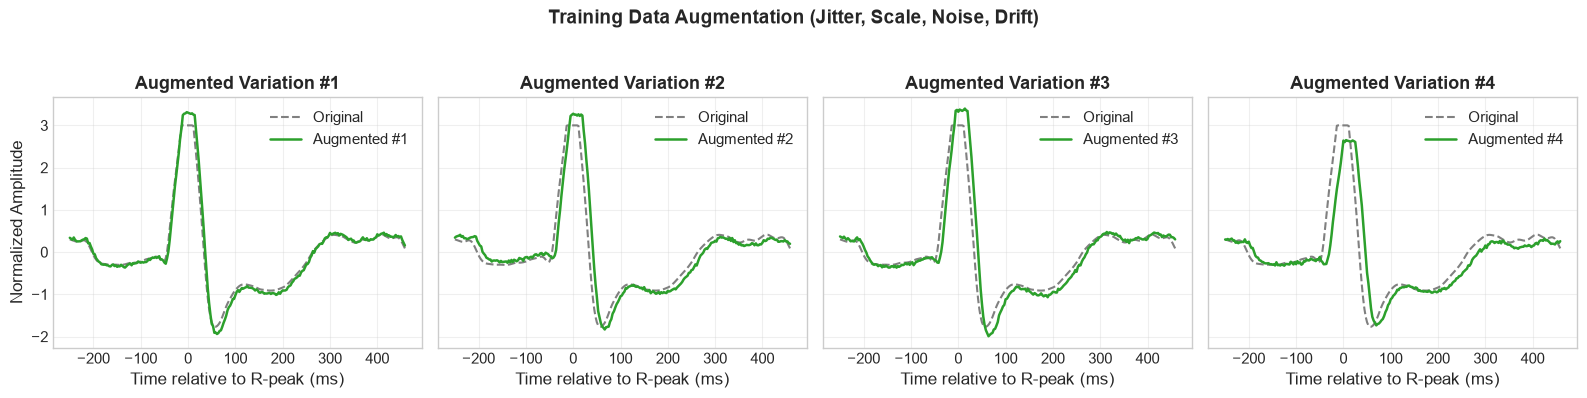

In [8]:
# Visualize Data Augmentation on a single heartbeat
sample_idx = 100
orig_beat, label = train_ds[sample_idx]
orig_beat = orig_beat[0]  # shape: (256,)

# Generate 4 distinct augmented versions
np.random.seed(42)
aug_ds = ECGDataset.from_npz(train_path, augment=True, to_torch=False)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)

for i in range(4):
  aug_beat, _ = aug_ds[sample_idx]
  aug_beat = aug_beat[0]
  axes[i].plot(
    time_ms, orig_beat, color="gray", linestyle="--", lw=1.5, label="Original"
  )
  axes[i].plot(time_ms, aug_beat, color="#2ca02c", lw=1.8, label=f"Augmented #{i + 1}")
  axes[i].set_title(f"Augmented Variation #{i + 1}", fontweight="bold")
  axes[i].set_xlabel("Time relative to R-peak (ms)")
  axes[i].grid(True, alpha=0.3)
  axes[i].legend(loc="upper right")

axes[0].set_ylabel("Normalized Amplitude")
plt.suptitle(
  "Training Data Augmentation (Jitter, Scale, Noise, Drift)",
  y=1.04,
  fontsize=14,
  fontweight="bold",
)
plt.tight_layout()
plt.show()

## 3.8 Final Dataset Summary (CRISP-DM Section 3.8 Table)

The finalized preprocessed datasets are saved as compressed NumPy archives:
- `dataset/processed/train.npz`
- `dataset/processed/val.npz`
- `dataset/processed/test.npz`

Each archive contains:
- `X`: Array of shape $(N, 1, 256)$, `float32`
- `y`: Array of shape $(N,)$, `int64` ($0$: N, $1$: S, $2$: V, $3$: F)
- `records`: Array of string record IDs for traceability
- `r_peaks`: Original R-peak sample indices
- `symbols`: Original MIT-BIH annotation symbols

In [9]:
# Load and display the official Section 3.8 dataset table from results
stats_csv_path = os.path.join("..", "results", "dataset_statistics.csv")
if not os.path.exists(stats_csv_path):
  stats_csv_path = os.path.join("results", "dataset_statistics.csv")

final_stats_df = pd.read_csv(stats_csv_path)
display(final_stats_df)

# Verify shapes of saved NPZ files
val_path = os.path.join("..", "dataset", "processed", "val.npz")
if not os.path.exists(val_path):
  val_path = os.path.join("dataset", "processed", "val.npz")

test_path = os.path.join("..", "dataset", "processed", "test.npz")
if not os.path.exists(test_path):
  test_path = os.path.join("dataset", "processed", "test.npz")

val_npz = np.load(val_path)
test_npz = np.load(test_path)

print("=== Preprocessed Array Shape Verification ===")
print(f"Train : X shape = {train_ds.X.shape}, y shape = {train_ds.y.shape}")
print(f"Val   : X shape = {val_npz['X'].shape}, y shape = {val_npz['y'].shape}")
print(f"Test  : X shape = {test_npz['X'].shape}, y shape = {test_npz['y'].shape}")

# Integrity check for NaNs or Infs
for name, arr in [
  ("Train", train_ds.X),
  ("Val", val_npz["X"]),
  ("Test", test_npz["X"]),
]:
  has_nan = np.isnan(arr).any()
  has_inf = np.isinf(arr).any()
  print(
    f"{name:<5}: NaN={has_nan} | Inf={has_inf} | Min={arr.min():.2f} | Max={arr.max():.2f}"
  )

,Split,Record Count,Records,N,S,V,F,Total
0,Train,17,"109, 112, 114, 115, 116, 119, 122, 124, 201, 2...",36008,838,3164,401,40411
1,Val,5,"101, 106, 108, 118, 205",9840,106,624,13,10583
2,Test,22,"100, 103, 105, 111, 113, 117, 121, 123, 200, 2...",44240,1837,3220,388,49685
3,Total,44,All 44 DS1+DS2 records,90088,2781,7008,802,100679


=== Preprocessed Array Shape Verification ===
Train : X shape = (40411, 1, 256), y shape = (40411,)
Val   : X shape = (10583, 1, 256), y shape = (10583,)
Test  : X shape = (49685, 1, 256), y shape = (49685,)


Train: NaN=False | Inf=False | Min=-3.00 | Max=3.00
Val  : NaN=False | Inf=False | Min=-3.00 | Max=3.00
Test : NaN=False | Inf=False | Min=-3.00 | Max=3.00


## 3.9 Reproducibility Audit

To guarantee exact reproducibility across platforms:

| Parameter | Configured Value |
| :--- | :--- |
| **Python Version** | `>= 3.14` |
| **Package Manager** | `uv` / `just` with locked `requirements.txt` |
| **Random Seed** | `42` |
| **Sampling Frequency ($f_s$)** | $360\text{ Hz}$ |
| **Selected Lead** | Modified Lead II (MLII) |
| **Bandpass Filter** | 3rd-order zero-phase Butterworth ($0.5\text{ Hz} - 40.0\text{ Hz}$) |
| **Window Length** | $256$ samples ($90$ pre-R, $166$ post-R) |
| **Normalization** | Per-beat Z-score Standardization |
| **Clipping Range** | $[-3.0, 3.0]$ standard deviations |
| **Train Records (17)** | `109, 112, 114, 115, 116, 119, 122, 124, 201, 203, 207, 208, 209, 215, 220, 223, 230` |
| **Validation Records (5)** | `101, 106, 108, 118, 205` |
| **Test Records (22)** | `100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234` |

In [10]:
# Save and print reproducibility summary
config_path = os.path.join("..", "configs", "preprocessing_config.yaml")
if not os.path.exists(config_path):
  config_path = os.path.join("configs", "preprocessing_config.yaml")

print(f"Configuration file verified at: {config_path}")
with open(config_path, "r") as f:
  print(f.read())

print("Data Preparation (CRISP-DM Stage 3) is complete and fully reproducible.")

Configuration file verified at: ..\configs\preprocessing_config.yaml
# Preprocessing Configuration for ECG Heartbeat Classification on Edge-AI
# Target Device: Analog Devices MAX78002

dataset:
  name: "MIT-BIH Arrhythmia Database"
  raw_dir: "dataset/physionet.org/files/mitdb/1.0.0"
  processed_dir: "dataset/processed"
  results_dir: "results"
  sampling_rate: 360  # Hz

signal_processing:
  lead: "MLII"
  bandpass:
    enabled: true
    lowcut: 0.5   # Hz (removes baseline wander)
    highcut: 40.0  # Hz (removes EMG and powerline noise)
    order: 3
  segmentation:
    window_size: 256  # 2^8 samples (711.1 ms @ 360 Hz)
    pre_r: 90         # 250.0 ms before R-peak (P-wave and PR interval)
    post_r: 166       # 461.1 ms after R-peak (QRS, ST segment, T-wave)
  normalization:
    method: "z-score"  # per-heartbeat standardization: (x - mean) / std
    clip_min: -3.0     # standard deviations
    clip_max: 3.0      # standard deviations

partitioning:
  # Inter-patient protocol (AA